In [4]:
import pandas as pd


In [5]:
df = pd.read_csv("penguins.csv", encoding='latin')
df.head(10)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,Female
7,Adelie,Torgersen,39.2,19.6,195.0,4675.0,Male
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN


In [7]:
df.shape

(344, 7)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [9]:
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


In [14]:
missing_values = df.isnull().sum()
missing_values

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

In [17]:
df["bill_length_mm"] = df["bill_length_mm"].fillna(df["bill_length_mm"].median())
df["bill_depth_mm"] = df["bill_depth_mm"].fillna(df["bill_depth_mm"].median())
df["flipper_length_mm"] = df["flipper_length_mm"].fillna(df["flipper_length_mm"].median())
df["body_mass_g"] = df["body_mass_g"].fillna(df["body_mass_g"].median())

**Handling Missing Numerical Values**

The numerical columns contain missing values. I filled them with their respective median values because the median is less affected by extreme values than the mean.

In [18]:
df["sex"] = df["sex"].fillna(df["sex"].mode()[0])


**Handling Missing Categorical Values**

The `sex` column contains missing values. I filled them with the most frequent category (mode) to complete the categorical data.

In [19]:
df.isnull().sum()

species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

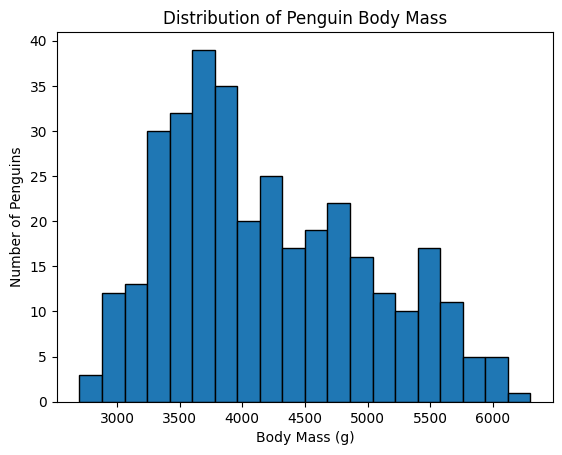

In [23]:
plt.hist(df["body_mass_g"], bins=20, edgecolor="black")

plt.xlabel("Body Mass (g)")
plt.ylabel("Number of Penguins")
plt.title("Distribution of Penguin Body Mass")
plt.show()

**Observation:** This histogram shows the distribution of penguin body mass. It helps identify the weight ranges in which most penguins fall and whether the distribution is spread out or concentrated.

In [29]:
Q1 = df["body_mass_g"].quantile(0.25)
Q3 = df["body_mass_g"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["body_mass_g"] < lower_bound) |
    (df["body_mass_g"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers))
outliers[["species", "body_mass_g"]]

Lower bound: 1750.0
Upper bound: 6550.0
Number of outliers: 0


,species,body_mass_g


**Outlier Analysis:** The IQR method identified no potential outliers in the body mass column. The lower bound was 1,750 g and the upper bound was 6,550 g. All body mass values fall within these boundaries.

### Box Plot of Penguin Body Mass

A box plot shows the distribution of penguin body mass and helps identify potential outliers in the dataset.

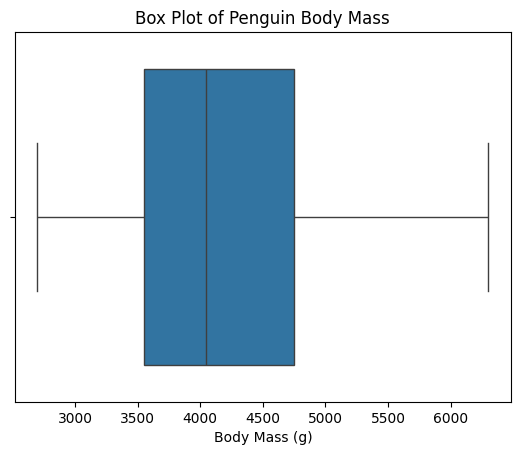

In [30]:
sns.boxplot(x=df["body_mass_g"])

plt.xlabel("Body Mass (g)")
plt.title("Box Plot of Penguin Body Mass")
plt.show()

In [35]:
columns = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(col, ":", count, "potential outliers")

bill_length_mm : 0 potential outliers
bill_depth_mm : 0 potential outliers
flipper_length_mm : 0 potential outliers
body_mass_g : 0 potential outliers


## Count Of Species

In [31]:
df["species"].value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

**Observation:** Adelie was the most common species with 152 penguins, followed by Gentoo with 124 and Chinstrap with 68. The dataset contains more Adelie penguins than the other two species.

In [32]:
df.groupby("species")["body_mass_g"].mean().round(2)

species
Adelie       3702.96
Chinstrap    3733.09
Gentoo       5067.74
Name: body_mass_g, dtype: float64

### Finding 2: Average Body Mass by Species

Gentoo penguins had the highest average body mass at 5,067.74 g, compared with 3,733.09 g for Chinstrap and 3,702.96 g for Adelie penguins.

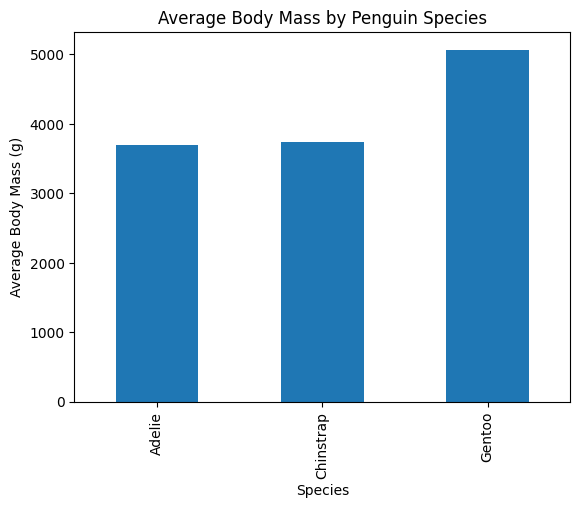

In [33]:
df.groupby("species")["body_mass_g"].mean().plot(kind="bar")

plt.xlabel("Species")
plt.ylabel("Average Body Mass (g)")
plt.title("Average Body Mass by Penguin Species")
plt.savefig("finding2_average_body_mass.png", bbox_inches="tight")
plt.show()

### Finding 3: Relationship Between Flipper Length and Body Mass

This analysis explores the relationship between penguin flipper length and body mass using correlation and a scatter plot.

In [34]:
df["flipper_length_mm"].corr(df["body_mass_g"]).round(2)

0.87

Correlation: 0.87


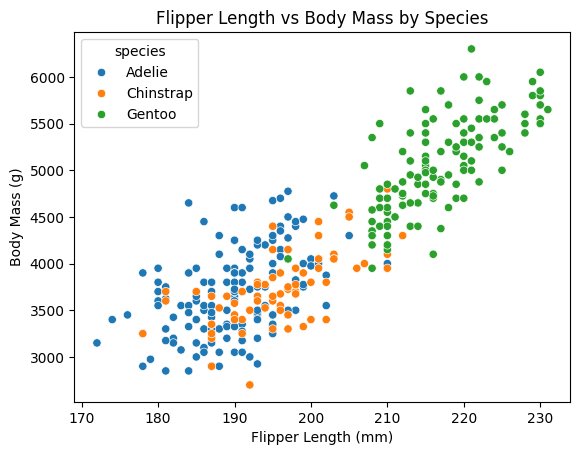

In [42]:
print("Correlation:", df["flipper_length_mm"].corr(df["body_mass_g"]).round(2))

sns.scatterplot(
    data=df,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species"
)

plt.xlabel("Flipper Length (mm)")
plt.ylabel("Body Mass (g)")
plt.title("Flipper Length vs Body Mass by Species")
plt.savefig("finding3_flipper_vs_body_mass.png", bbox_inches="tight")
plt.show()

**Observation:** Flipper length and body mass have a strong positive correlation of 0.87. This indicates that penguins with longer flippers generally tend to have higher body mass.

## Conclusion

The Penguins dataset contains 344 records representing three species: Adelie, Gentoo, and Chinstrap. Adelie was the most common species, with 152 penguins, while Gentoo had the highest average body mass at 5,067.74 g. Flipper length and body mass showed a strong positive correlation of 0.87. Missing values were handled using median and mode imputation, and the IQR method detected no potential outliers in the four numerical features. Overall, the analysis helped identify patterns and differences among penguin species.